## Linear Programming Optimization

#### Examples 

In [1]:
from scipy.optimize import linprog

# Example 1: Maximizing Profit (Converted to Minimization)
# Objective function (negative because linprog minimizes):
c1 = [-20, -30]  # Coefficients for Tables (T) and Chairs (C)

# Constraints:
A1 = [
    [2, 1],  # 2T + C <= 40 (Wood constraint)
    [1, 2]   # T + 2C <= 50 (Labor constraint)
]
b1 = [40, 50]  # Right-hand side of the constraints

# Bounds:
x1_bounds = (0, None)  # T >= 0
x2_bounds = (0, None)  # C >= 0

# Solve the problem:
result1 = linprog(c1, A_ub=A1, b_ub=b1, bounds=[x1_bounds, x2_bounds], method='highs')

print("Example 1: Maximizing Profit")
print("Optimal solution:", result1.x)
print("Maximum profit:", -result1.fun)



Example 1: Maximizing Profit
Optimal solution: [10. 20.]
Maximum profit: 800.0


In [2]:
# Example 2: Minimizing Cost
# Objective function:
c2 = [5, 3]  # Coefficients for Machine A (x1) and Machine B (x2)

# Constraints:
A2 = [
    [-1, -1],  # x1 + x2 >= 100 converted to -x1 - x2 <= -100
    [1, 0],    # x1 <= 60
    [0, 1]     # x2 <= 80
]
b2 = [-100, 60, 80]  # Right-hand side of the constraints

# Bounds:
x1_bounds = (0, None)  # x1 >= 0
x2_bounds = (0, None)  # x2 >= 0

# Solve the problem:
result2 = linprog(c2, A_ub=A2, b_ub=b2, bounds=[x1_bounds, x2_bounds], method='highs')

print("\nExample 2: Minimizing Cost")
print("Optimal solution:", result2.x)
print("Minimum cost:", result2.fun)



Example 2: Minimizing Cost
Optimal solution: [20. 80.]
Minimum cost: 340.0


#### Task

Imagine you have a bakery that produces two types of cakes: chocolate cakes and vanilla cakes. To make each chocolate cake, you need 2 cups of flour, 1 cup of sugar, and 3 eggs. To make each vanilla cake, you need 1 cup of flour, 2 cups of sugar, and 2 eggs. You have 30 cups of flour, 40 cups of sugar, and 50 eggs available.

Your goal is to maximize profit. Each chocolate cake sells for 10, and each vanilla cake sells for 8.

Linear Programming Optimization (Maximize, minimize a number).
- Maximize the profit.
- Minimize risk.



1- Decision Varibales. (1- Chocolate Cake. 2- Vanilla Cake) <=== Decision varibles
2- Constraints.
-> Choclate Cake(x0) : 2 cups flour , 1 cup sugar, 3 eggs
-> Vanilla Cake(x1) : 1 cup of flour, 2 cups of sugar, 2 eggs.
Constraints:
- flour: 2 x0 + 1 x1 <= 30 (chocolate cake + vanilla cake)
- sugar: 1 x0 + 2 x1 <= 40
- egg: 3 x0 + 2 x1 <= 50

3- Objective Function.
choclate cake -> 10
Vanilla cake -> 8
To maximize the profit.
Objective function 10*x0 + 8*x1

In [7]:
from scipy.optimize import linprog

# By default it work to minimize so we put minus with the coeffeinicts to covert them to positive (Maximize)
# Define the coefficients of the objective function
c = [-10, -8]  # Coefficients for maximizing profit: -10 for chocolate cakes, -8 for vanilla cakes

# Define the coefficients of the constraints (left-hand side matrix) 2D list
A = [
    [2, 1],  # Flour constraint coefficients
    [1, 2],  # Sugar constraint coefficients
    [3, 2]   # Eggs constraint coefficients
]

# Define the right-hand side of the constraints 1D list
b = [30, 40, 50]  # Available amounts of flour, sugar, and eggs

# Define the bounds for each variable (non-negative) Decision variables
x0_bounds = (0, None)  # Chocolate cakes
x1_bounds = (0, None)  # Vanilla cakes

# Solve the linear programming problem (highs --> to minimze , simplex --> to maxximize)

result = linprog(c, A_ub=A, b_ub=b, bounds=[x0_bounds, x1_bounds], method='highs')

# Print the result (result , x[0] --> number of chocolate cake , x[1] --> number of vanilla cake , result.fun(maximum profit fun is a constant variable in result (maximum value or minimum value))
print("Number of chocolate cakes:", round(result.x[0]))
print("Number of vanilla cakes:", round(result.x[1]))
# Objective_function = 10*5 + 8*18 = (result.fun)
print("Maximum profit: $", -round(result.fun))  # Multiplying by -1 because linprog minimizes by default

# Objective function coefficients for maximizing profit
c = [-10, -8]

# Objective function (to maximize profit)
# The objective function is the sum of the product of coefficients and decision variables
objective_function = f"Maximize: {-c[0]} * x0 + {-c[1]} * x1"

print("Objective function:")
print(objective_function)

Number of chocolate cakes: 5
Number of vanilla cakes: 18
Maximum profit: $ 190
Objective function:
Maximize: 10 * x0 + 8 * x1


## GA 


### **Example: Diet Optimization Problem**

A nutritionist wants to plan a **daily diet** using **3 types of food**: Rice, Chicken, and Beans. Each food has a cost and provides protein and calories as follows:

| Food    | Cost per serving ($) | Protein per serving (g) | Calories per serving |
| ------- | -------------------- | ----------------------- | -------------------- |
| Rice    | 2                    | 2                       | 200                  |
| Chicken | 5                    | 10                      | 250                  |
| Beans   | 3                    | 5                       | 150                  |

---

### **Decision Variables**

* ( x_1 ) = number of servings of Rice
* ( x_2 ) = number of servings of Chicken
* ( x_3 ) = number of servings of Beans

All ( x_i>=0 ) and must be integers.

---

### **Objective Function**

Minimize the **total cost** of the diet:


Minimize  C = 2x_1 + 5x_2 + 3x_3


---

### **Constraints**

1. **Protein requirement:**
   
   2x_1 + 10x_2 + 5x_3 >= 50
   

2. **Calorie requirement:**
   
   200x_1 + 250x_2 + 150x_3 >= 2000
   

3. **Non-negativity:**
   
   x_1, x_2, x_3 >= 0
   

---

### **Task**

Use a **Genetic Algorithm (GA)** to determine the **number of servings for each food** that satisfies all constraints while **minimizing the total cost**.

**Expected outputs:**

* Optimal number of servings of Rice, Chicken, and Beans
* Total cost
* Total protein and calories

In [4]:
!pip install pygad

C:\Users\Asma.AlFakhore\Anaconda3\lib\site-packages\pygad\pygad.py:753: UserWarning: The percentage of genes to mutate (mutation_percent_genes=20) resulted in selecting (0) genes. The number of genes to mutate is set to 1 (mutation_num_genes=1).
If you do not want to mutate any gene, please set mutation_type=None.
  warnings.warn(f"The percentage of genes to mutate (mutation_percent_genes={mutation_percent_genes}) resulted in selecting ({mutation_num_genes}) genes. The number of genes to mutate is set to 1 (mutation_num_genes=1).\nIf you do not want to mutate any gene, please set mutation_type=None.")


Optimal servings:
Rice = 5, Chicken = 1, Beans = 6
Total Cost = $33
Total Protein = 50 g
Total Calories = 2150


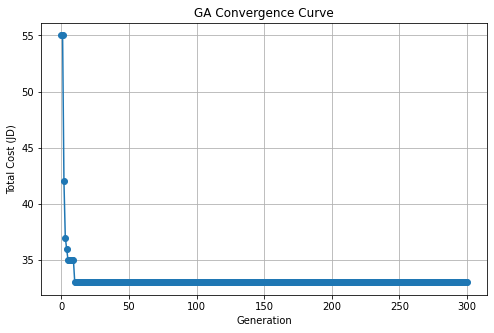

In [8]:

import pygad
import numpy as np

def fitness_func(ga_instance, solution, solution_idx):
    x1, x2, x3 = solution

    # Enforce non-negativity
    if x1 < 0 or x2 < 0 or x3 < 0:
        return -99999

    # Constraints
    protein = 2*x1 + 10*x2 + 5*x3
    calories = 200*x1 + 250*x2 + 150*x3

    if protein < 50:
        return -99999

    if calories < 2000:
        return -99999

    # Cost to MINIMIZE
    cost = 2*x1 + 5*x2 + 3*x3

    # Convert minimization → maximization
    return -cost


# GA instance
ga_instance = pygad.GA(
    num_generations=300,
    sol_per_pop=30,
    num_parents_mating=10,
    fitness_func=fitness_func,
    num_genes=3,
    gene_type=int,
    init_range_low=0,
    init_range_high=50,
    mutation_percent_genes=20,
    keep_elitism=2
)

# Run GA
ga_instance.run()

# Best solution
solution, solution_fitness, _ = ga_instance.best_solution()
x1, x2, x3 = solution

cost = 2*x1 + 5*x2 + 3*x3
protein = 2*x1 + 10*x2 + 5*x3
calories = 200*x1 + 250*x2 + 150*x3

print(f"Optimal servings:")
print(f"Rice = {x1}, Chicken = {x2}, Beans = {x3}")
print(f"Total Cost = ${cost}")
print(f"Total Protein = {protein} g")
print(f"Total Calories = {calories}")


import matplotlib.pyplot as plt
# Retrieve the best fitness value at each generation
best_fitness_values = ga_instance.best_solutions_fitness

# Convert fitness to positive cost
best_cost_values = [-f for f in best_fitness_values]

plt.figure(figsize=(8,5))
plt.plot(best_cost_values, marker='o')
plt.title("GA Convergence Curve")
plt.xlabel("Generation")
plt.ylabel("Total Cost (JD)")
plt.grid(True)
plt.show()





### **Question : Bakery Production Optimization Problem**

A bakery produces **two types of cakes**: **Chocolate cakes** and **Vanilla cakes**.
Each cake requires specific ingredients, and the bakery has limited resources.

| Cake Type | Flour (cups) | Sugar (cups) | Eggs | Profit per cake ($) |
| --------- | ------------ | ------------ | ---- | ------------------- |
| Chocolate | 2            | 1            | 3    | 10                  |
| Vanilla   | 1            | 2            | 2    | 8                   |

The bakery has the following **available resources**:

* 30 cups of flour
* 40 cups of sugar
* 50 eggs

---

### **Decision Variables**

* ( x_1 ) = number of **Chocolate cakes** produced
* ( x_2 ) = number of **Vanilla cakes** produced

All variables must satisfy:
( x_1, x_2 > 0 ) and must be integers.

---

### **Objective Function**

Maximize the **total profit**:

Maximize  P = 10x_1 + 8x_2


---

### **Constraints**

1. **Flour constraint:**
   
   2x_1 + x_2 <= 30
   

2. **Sugar constraint:**
   
   x_1 + 2x_2 <= 40
   

3. **Egg constraint:**
   
   3x_1 + 2x_2 <= 50
   

4. **Non-negativity and integrality:**
   
   x_1, x_2 > 0 and integers
   

---

### **Task**

Use a **Genetic Algorithm (GA)** to determine the **optimal number of chocolate and vanilla cakes** that:

* Satisfy all ingredient constraints
* **Maximize total profit**


---

### **Expected Outputs**

* Optimal number of Chocolate cakes and Vanilla cakes
* Maximum profit
* Amount of flour, sugar, and eggs used
* plot the convergence




In [5]:
import pygad
import numpy as np

def fitness_func(ga_instance, solution, solution_idx):
    x1, x2 = solution

    # Force integer values
    x1 = int(round(x1))
    x2 = int(round(x2))

    # Non-negativity
    if x1 < 0 or x2 < 0:
        return -99999

    # Resource constraints
    if 2*x1 + x2 > 30:   # Flour
        return -99999

    if x1 + 2*x2 > 40:  # Sugar
        return -99999

    if 3*x1 + 2*x2 > 50:  # Eggs
        return -99999

    # Profit (maximize)
    profit = 10*x1 + 8*x2
    return profit


ga_instance = pygad.GA(
    num_generations=100,
    num_parents_mating=10,
    fitness_func=fitness_func,
    sol_per_pop=20,
    num_genes=2,
    gene_type=float,     
    init_range_low=0,
    init_range_high=50,
    parent_selection_type="tournament",
    crossover_type="single_point",
    mutation_type="random",
    mutation_percent_genes=50
)

ga_instance.run()

solution, solution_fitness, solution_idx = ga_instance.best_solution()

# Convert to integers for final answer
x1 = int(round(solution[0]))
x2 = int(round(solution[1]))

print("Best solution:")
print(f"Chocolate cakes: {x1}")
print(f"Vanilla cakes: {x2}")
print(f"Maximum profit: {solution_fitness}")


Best solution:
Chocolate cakes: 10
Vanilla cakes: 10
Maximum profit: 180


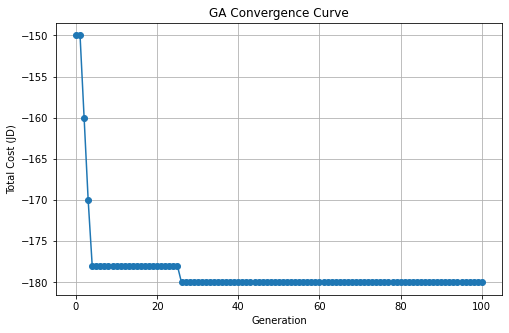

In [6]:
import matplotlib.pyplot as plt
# Retrieve the best fitness value at each generation
best_fitness_values = ga_instance.best_solutions_fitness

# Convert fitness to positive cost
best_cost_values = [-f for f in best_fitness_values]

plt.figure(figsize=(8,5))
plt.plot(best_cost_values, marker='o')
plt.title("GA Convergence Curve")
plt.xlabel("Generation")
plt.ylabel("Total Cost (JD)")
plt.grid(True)
plt.show()